# Agrupamiento de subpartidas con K-means

Se comparan tres configuraciones de indicadores (E1, E2 y E3) para agrupar las subpartidas según su comportamiento exportador entre 2011 y 2025. Para cada configuración se estandarizan los indicadores, se evalúan soluciones de dos a ocho grupos y se generan sus gráficos.

La evaluación incluye los índices de silueta, Davies-Bouldin y Calinski-Harabasz, así como la estabilidad de los grupos mediante submuestreo. También se comparan las asignaciones de E1, E2 y E3 mediante el índice de Rand ajustado (ARI) para dos y tres grupos.

La solución seleccionada en la tesis es E1 con tres grupos.

## Archivo de entrada

`datos/procesados/indicadores_subpartidas_2011_2025.parquet`, generado por el cuaderno 03.

## Clasificación final

`resultados/clustering/subpartidas_E1_k3_FINAL.csv` contiene una fila por subpartida homologada y su grupo asignado en la columna `grupo_E1`. El cuaderno 05 utiliza este archivo para caracterizar los tres grupos.

In [1]:
# Se importan las dependencias necesarias
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram

## 1. Parámetros

In [2]:
# 1. Configuración de rutas y parámetros de los modelos.
# Ruta del archivo de indicadores generado en el cuaderno anterior.
ruta_indicadores = Path("datos/procesados/indicadores_subpartidas_2011_2025.parquet")

# Carpeta de resultados de K-means
carpeta_salida = Path("resultados/clustering")
carpeta_salida.mkdir(parents=True, exist_ok=True)

# Definición de las variables de entrada para cada configuración.
modelos = {
    # E1: configuración base con cinco indicadores.
    "E1": [
        "log_fob_total",
        "anios_activos",
        "episodios_exportadores",
        "regularidad_mensual",
        "hhi_destinos_periodo"
    ],

    # E2: configuración base con incorporación de la recencia exportadora.
    "E2": [
        "log_fob_total",
        "anios_activos",
        "episodios_exportadores",
        "regularidad_mensual",
        "hhi_destinos_periodo",
        "anios_desde_ultimo_activo"
    ],

    # E3: configuración base con incorporación de la tendencia económica.
    "E3": [
        "log_fob_total",
        "anios_activos",
        "episodios_exportadores",
        "regularidad_mensual",
        "hhi_destinos_periodo",
        "pendiente_log_fob_anual"
    ]
}

# Variables a transformar con logaritmo antes de la estandarización. Por defecto, no se aplica una transformación adicional.
columnas_log = []

# Números de grupos que se prueban
rango_k = range(2, 9)

# Algoritmo que se usa en el análisis
metodos = ["kmeans"]

# Algoritmo utilizado para obtener los grupos finales.
metodo_final = "kmeans"

# Número de grupos por modelo. 
# None permite utilizar provisionalmente el valor de K con mayor silueta.
# La selección definitiva se realiza después de revisar los resultados.
k_elegido = {"E1": None, "E2": None, "E3": None}

# Parámetros de ejecución y estabilidad de los agrupamientos.
n_init = 20
semilla = 42

# Número de repeticiones y proporción de subpartidas utilizadas en cada muestra.
n_repeticiones = 20
proporcion_muestra = 0.8

# Configuración de las representaciones gráficas.
guardar_figuras = True

# Guardado de los gráficos correspondientes a todos los valores de K evaluados.
guardar_todos_los_k = True

Los resultados se guardarán en: C:\Users\Udep titulación\Downloads\TESIS_HOMOLOGACION_SUBPARTIDAS\Clustering_E1_E2_E3_v3


## 2. Lectura de los indicadores

In [3]:
def leer(ruta):
    """Lee un archivo parquet o csv."""
    if ruta.suffix == ".parquet":
        return pd.read_parquet(ruta)
    if ruta.suffix == ".csv":
        return pd.read_csv(ruta, dtype={"subpartida_homologada": str})
    raise ValueError(f"Formato no reconocido: {ruta.suffix}")

# Lectura de los indicadores y revisión de su estructura.
ind = leer(ruta_indicadores)
print("Subpartidas:", len(ind))
print("Columnas:", list(ind.columns))

Subpartidas: 5626
Columnas: ['subpartida_homologada', 'fob_total_mill', 'log_fob_total', 'anios_activos', 'episodios_exportadores', 'meses_activos', 'regularidad_mensual', 'hhi_destinos_periodo', 'mercados_distintos_periodo', 'anios_desde_ultimo_activo', 'pendiente_log_fob_anual', 'log_fob_medio_anio_activo']


## 3. Preparación y evaluación de cada modelo
Las variables se estandarizan (media 0 y desviación 1) para que ninguna pese más por su escala.
Luego se agrupa con k-means para cada número de grupos, y se calculan la silueta y el índice de Davies-Bouldin.

In [4]:
def preparar(modelo):
    """Selecciona los datos completos y estandariza las variables del modelo."""
    columnas = modelos[modelo]
    datos = ind.dropna(subset=columnas).copy()
    valores = datos[columnas].copy()
    for c in columnas_log:
        if c in valores:
            valores[c] = np.log1p(valores[c])
    X = StandardScaler().fit_transform(valores)
    return datos, X


def agrupar(X, k, metodo, Z=None):
    """Asigna las subpartidas a k grupos mediante el método seleccionado."""
    if metodo == "kmeans":
        return KMeans(n_clusters=k, n_init=n_init, random_state=semilla).fit_predict(X)
    return fcluster(Z, k, criterion="maxclust") - 1


def evaluar(X):
    """Calcula los índices de validación interna para cada método y valor de K."""
    Z = linkage(X, method="ward") if "jerarquico" in metodos else None
    filas = []
    base = {}
    for metodo in metodos:
        for k in rango_k:
            lab = agrupar(X, k, metodo, Z)
            base[(metodo, k)] = lab
            filas.append({"metodo": metodo, "k": k,
                          "silueta": silhouette_score(X, lab),
                          "davies_bouldin": davies_bouldin_score(X, lab),
                          "calinski_harabasz": calinski_harabasz_score(X, lab)})
    return pd.DataFrame(filas), Z, base


def estabilidad(X, base):
    """Repite el agrupamiento en muestras al azar y lo compara con el agrupamiento completo.
    Se usa el índice de Rand ajustado (1 = mismos grupos; cerca de 0 = grupos distintos)."""
    rng = np.random.default_rng(semilla)
    tam = int(proporcion_muestra * len(X))
    ari = {clave: [] for clave in base}
    for _ in range(n_repeticiones):
        idx = rng.choice(len(X), size=tam, replace=False)
        Xm = X[idx]
        Zm = linkage(Xm, method="ward") if "jerarquico" in metodos else None
        for (metodo, k), lab_completo in base.items():
            lab = agrupar(Xm, k, metodo, Zm)
            ari[(metodo, k)].append(adjusted_rand_score(lab_completo[idx], lab))
    return pd.DataFrame([{"metodo": m, "k": k, "estabilidad": np.mean(v)} for (m, k), v in ari.items()])

# Ejecución de los modelos y consolidación de las métricas de evaluación.
resultados = {}
for m in modelos:
    datos, X = preparar(m)
    metricas, Z, base = evaluar(X)
    metricas = metricas.merge(estabilidad(X, base), on=["metodo", "k"])
    resultados[m] = {"datos": datos, "X": X, "metricas": metricas, "Z": Z}
    print(f"Modelo {m}: {len(datos)} subpartidas, {len(modelos[m])} variables")

Modelo E1: 5626 subpartidas, 5 variables
Modelo E2: 5626 subpartidas, 6 variables
Modelo E3: 5626 subpartidas, 6 variables


## 4. Selección del número de grupos
Para cada modelo se muestra cómo cambian, al aumentar k:
- la **silueta** (mejor cuanto mayor),
- el **Davies-Bouldin** (mejor cuanto menor),
- el **Calinski-Harabasz** (mejor cuanto mayor; tiende a crecer con k, así que se mira dónde deja de mejorar),
- la **estabilidad** (índice de Rand ajustado entre el agrupamiento completo y agrupamientos con el 80 % de las subpartidas; cerca de 1 es estable).

Los valores no bastan por sí solos: hay que mirar también los gráficos de la sección 6 antes de decidir.

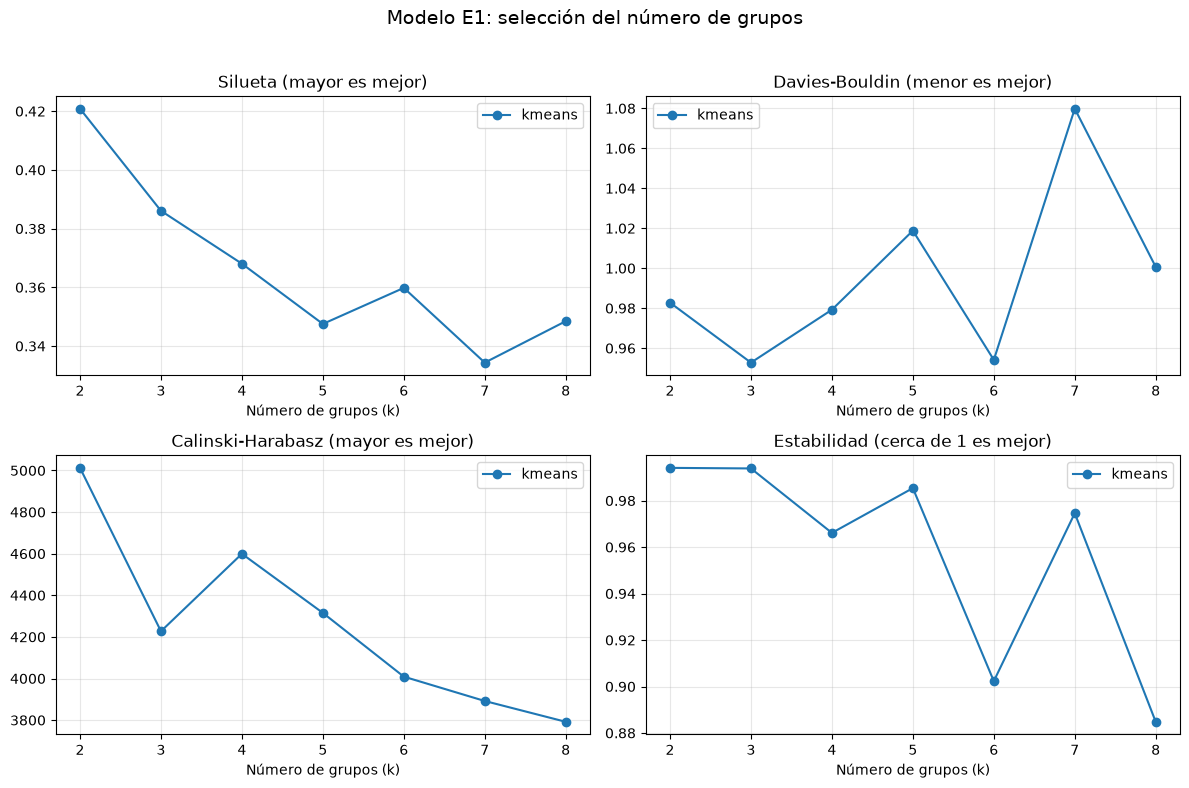

Modelo E1
          silueta  davies_bouldin  calinski_harabasz  estabilidad
metodo k                                                         
kmeans 2    0.421           0.983           5012.532        0.994
       3    0.386           0.953           4227.120        0.994
       4    0.368           0.979           4599.469        0.966
       5    0.348           1.019           4315.328        0.985
       6    0.360           0.954           4008.901        0.902
       7    0.334           1.080           3891.866        0.975
       8    0.348           1.001           3791.863        0.885



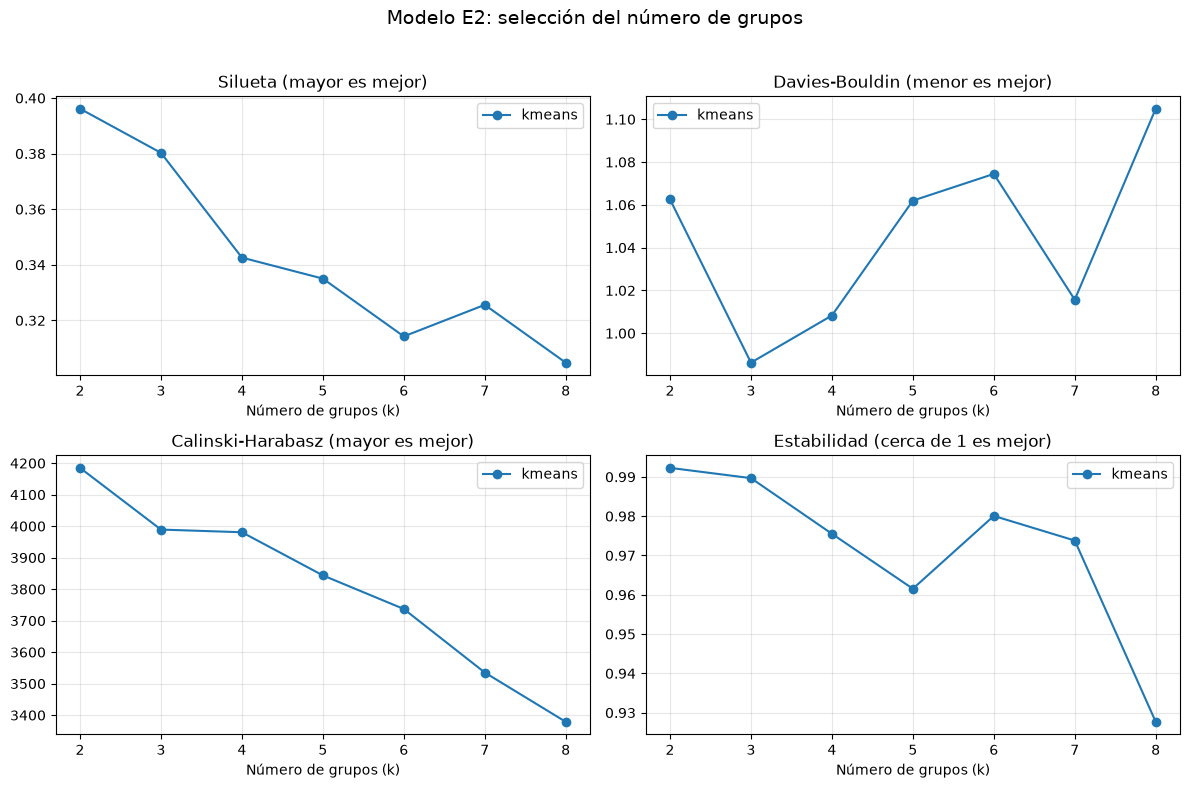

Modelo E2
          silueta  davies_bouldin  calinski_harabasz  estabilidad
metodo k                                                         
kmeans 2    0.396           1.063           4185.077        0.992
       3    0.380           0.986           3989.174        0.990
       4    0.343           1.008           3980.712        0.976
       5    0.335           1.062           3843.753        0.962
       6    0.314           1.074           3737.050        0.980
       7    0.326           1.016           3535.373        0.974
       8    0.305           1.105           3378.925        0.928



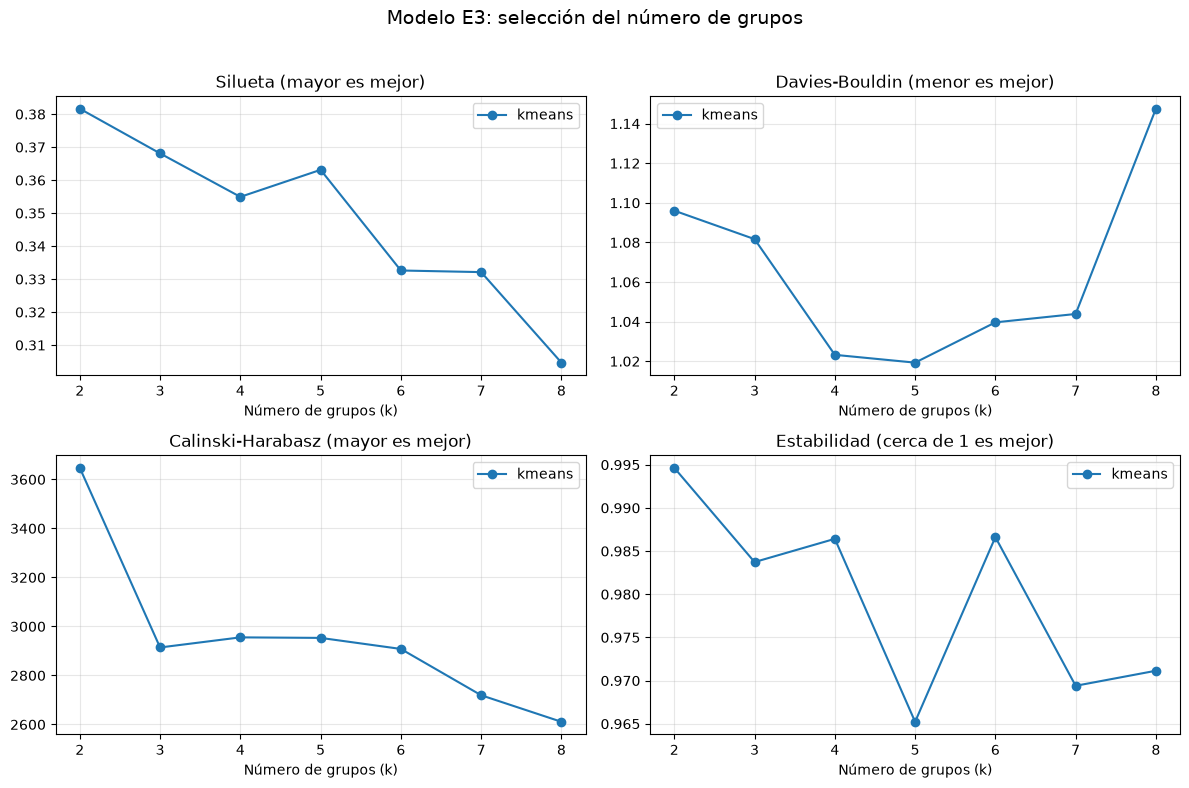

Modelo E3
          silueta  davies_bouldin  calinski_harabasz  estabilidad
metodo k                                                         
kmeans 2    0.382           1.096           3647.087        0.995
       3    0.368           1.082           2914.170        0.984
       4    0.355           1.023           2955.381        0.986
       5    0.363           1.019           2953.241        0.965
       6    0.333           1.040           2908.126        0.987
       7    0.332           1.044           2719.189        0.969
       8    0.305           1.148           2610.826        0.971



In [5]:
# Función para guardar las figuras en la carpeta de resultados.
def guardar(fig, nombre):
    if guardar_figuras:
        carpeta_fig = carpeta_salida / "figuras"
        carpeta_fig.mkdir(parents=True, exist_ok=True)
        fig.savefig(carpeta_fig / nombre, dpi=200, bbox_inches="tight")

# Métricas utilizadas para evaluar la calidad y estabilidad de los agrupamientos.
indices = [("silueta", "Silueta (mayor es mejor)"),
           ("davies_bouldin", "Davies-Bouldin (menor es mejor)"),
           ("calinski_harabasz", "Calinski-Harabasz (mayor es mejor)"),
           ("estabilidad", "Estabilidad (cerca de 1 es mejor)")]

# Representación gráfica y resumen de las métricas para cada modelo.
for m in modelos:
    metricas = resultados[m]["metricas"]
    fig, ejes = plt.subplots(2, 2, figsize=(12, 8))
    fig.suptitle(f"Modelo {m}: selección del número de grupos", fontsize=14)
    for eje, (columna, titulo) in zip(ejes.ravel(), indices):
        for metodo, g in metricas.groupby("metodo"):
            eje.plot(g["k"], g[columna], marker="o", label=metodo)
        eje.set_title(titulo)
        eje.set_xlabel("Número de grupos (k)")
        eje.set_xticks(list(rango_k))
        eje.grid(alpha=0.3)
        eje.legend()
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    guardar(fig, f"seleccion_k_modelo_{m}.png")
    plt.show()

    # Presentación de los valores de las métricas para cada K evaluado.
    print(f"Modelo {m}")
    print(metricas.set_index(["metodo", "k"]).round(3).to_string())
    print()

## 5. Número de grupos y asignación
Se usa el k indicado en `k_elegido`. Si es `None`, se usa un k provisional, el de mayor silueta para el método final, que no debe tomarse como decisión definitiva.
Los grupos se numeran del más grande al más pequeño.

In [6]:
# Selección del número de grupos para cada modelo.
def elegir_k(modelo):
    if k_elegido.get(modelo):
        return k_elegido[modelo]
    metricas = resultados[modelo]["metricas"]
    metricas = metricas[metricas["metodo"] == metodo_final]
    return int(metricas.loc[metricas["silueta"].idxmax(), "k"])


# Asignación de etiquetas finales, ordenadas según el tamaño de los grupos.
def asignar(modelo, k, metodo=None):
    """Asigna etiquetas consecutivas a los grupos, de mayor a menor tamaño."""
    metodo = metodo or metodo_final
    lab = agrupar(resultados[modelo]["X"], k, metodo, resultados[modelo]["Z"])
    orden = pd.Series(lab).value_counts().index
    nuevo = {viejo: i + 1 for i, viejo in enumerate(orden)}
    return pd.Series(lab, index=resultados[modelo]["datos"].index).map(nuevo)


# Determinación de K y generación de las etiquetas finales para cada modelo.
k_usado = {m: elegir_k(m) for m in modelos}
etiquetas = {m: asignar(m, k_usado[m]) for m in modelos}

# Advertencia cuando el número de grupos se selecciona automáticamente.
for m in modelos:
    if not k_elegido.get(m):
        print(f"Aviso: el k del modelo {m} es provisional ({k_usado[m]}). Revisar los gráficos antes de fijarlo.")

# Consolidación de las métricas de evaluación de los agrupamientos finales.
resumen = []
for m in modelos:
    X, lab = resultados[m]["X"], etiquetas[m].to_numpy()
    tabla_m = resultados[m]["metricas"]
    estab = tabla_m[(tabla_m["metodo"] == metodo_final) & (tabla_m["k"] == k_usado[m])]["estabilidad"]
    resumen.append({"modelo": m, "variables": len(modelos[m]), "metodo": metodo_final,
                    "k": k_usado[m],
                    "silueta": round(silhouette_score(X, lab), 3),
                    "davies_bouldin": round(davies_bouldin_score(X, lab), 3),
                    "calinski_harabasz": round(calinski_harabasz_score(X, lab), 1),
                    "estabilidad": round(float(estab.iloc[0]), 3)})

# Presentación del resumen comparativo de los modelos.
print()
print(pd.DataFrame(resumen).to_string(index=False))

Aviso: el k del modelo E1 es provisional (2). Revisar los gráficos antes de fijarlo.
Aviso: el k del modelo E2 es provisional (2). Revisar los gráficos antes de fijarlo.
Aviso: el k del modelo E3 es provisional (2). Revisar los gráficos antes de fijarlo.

modelo  variables metodo  k  silueta  davies_bouldin  calinski_harabasz  estabilidad
    E1          5 kmeans  2    0.421           0.983             5012.5        0.994
    E2          6 kmeans  2    0.396           1.063             4185.1        0.992
    E3          6 kmeans  2    0.382           1.096             3647.1        0.995


## 6. Gráficos de cada modelo
Para cada modelo se presentan:
1. Tamaño de los grupos.
2. Diagrama de silueta: cada barra es una subpartida; barras largas indican que está bien ubicada y negativas, que quizá pertenece a otro grupo. La línea roja es la silueta promedio.
3. Proyección en dos dimensiones (PCA) permite ver si los grupos se separan o se superponen.
4. Perfil de los grupos: promedio de cada variable estandarizada. Rojo indica que el grupo está por encima del promedio general y azul, por debajo.

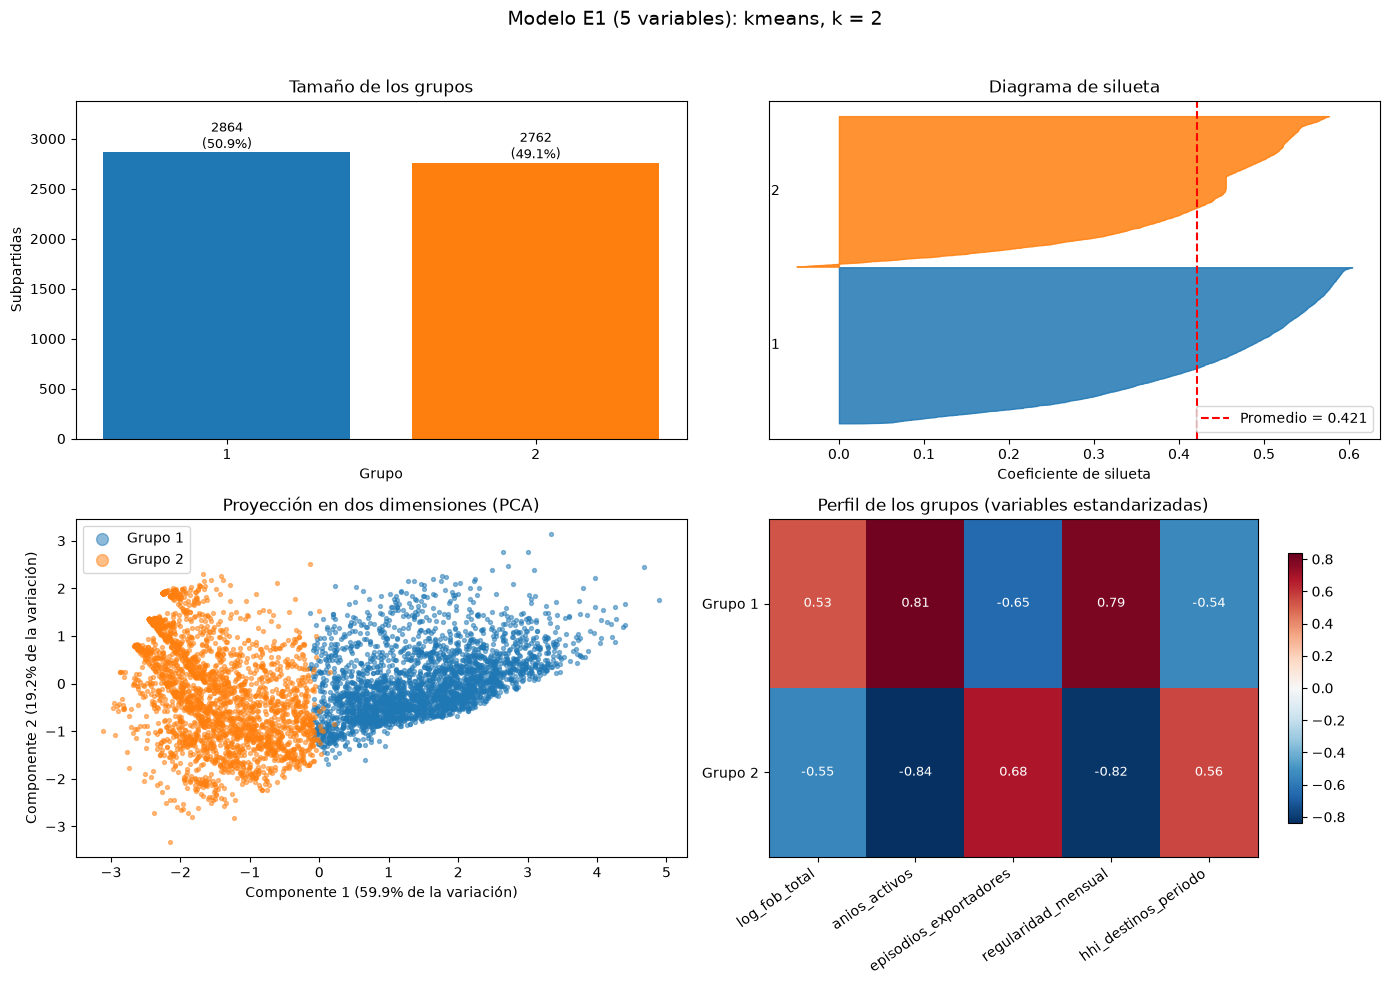

Promedios por grupo, modelo E1 (unidades originales)
       subpartidas  log_fob_total  anios_activos  episodios_exportadores  regularidad_mensual  hhi_destinos_periodo
grupo                                                                                                              
1             2864           1.93           14.7                    1.13                 0.70                  0.34
2             2762           0.22            6.4                    2.67                 0.16                  0.64



In [7]:
# Paleta de colores para representar los grupos.
colores = plt.cm.tab10.colors


def graficar_modelo(modelo, k, metodo=None, mostrar=True):
    metodo = metodo or metodo_final
    datos = resultados[modelo]["datos"]
    X = resultados[modelo]["X"]
    columnas = modelos[modelo]
    lab = asignar(modelo, k, metodo).to_numpy()
    grupos = sorted(set(lab))
    k = len(grupos)

    fig, ejes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f"Modelo {modelo} ({len(columnas)} variables): {metodo}, k = {k}", fontsize=14)

    # 1. Distribución de las subpartidas por grupo.
    tamanos = pd.Series(lab).value_counts().sort_index()
    ejes[0, 0].bar(tamanos.index.astype(str), tamanos.values, color=[colores[g - 1] for g in tamanos.index])
    for i, v in enumerate(tamanos.values):
        ejes[0, 0].text(i, v, f"{v}\n({v / len(lab):.1%})", ha="center", va="bottom", fontsize=9)
    ejes[0, 0].set_title("Tamaño de los grupos")
    ejes[0, 0].set_xlabel("Grupo")
    ejes[0, 0].set_ylabel("Subpartidas")
    ejes[0, 0].set_ylim(0, tamanos.max() * 1.18)

    # 2. Distribución de los coeficientes de silueta por grupo.
    sil = silhouette_samples(X, lab)
    y_inicio = 10
    for g in grupos:
        s = np.sort(sil[lab == g])
        y_fin = y_inicio + len(s)
        ejes[0, 1].fill_betweenx(np.arange(y_inicio, y_fin), 0, s, color=colores[g - 1], alpha=0.85)
        ejes[0, 1].text(-0.08, y_inicio + len(s) / 2, str(g), va="center")
        y_inicio = y_fin + 10
    ejes[0, 1].axvline(sil.mean(), color="red", linestyle="--", label=f"Promedio = {sil.mean():.3f}")
    ejes[0, 1].set_title("Diagrama de silueta")
    ejes[0, 1].set_xlabel("Coeficiente de silueta")
    ejes[0, 1].set_yticks([])
    ejes[0, 1].legend(loc="lower right")

    # 3. Representación de los grupos mediante componentes principales (PCA).
    pca = PCA(n_components=2, random_state=semilla)
    P = pca.fit_transform(X)
    for g in grupos:
        punto = lab == g
        ejes[1, 0].scatter(P[punto, 0], P[punto, 1], s=8, alpha=0.5, color=colores[g - 1], label=f"Grupo {g}")
    ejes[1, 0].set_title("Proyección en dos dimensiones (PCA)")
    ejes[1, 0].set_xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]:.1%} de la variación)")
    ejes[1, 0].set_ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]:.1%} de la variación)")
    ejes[1, 0].legend(markerscale=3)

    # 4. Perfil promedio de los grupos en las variables estandarizadas.
    perfil = pd.DataFrame(X, columns=columnas).groupby(lab).mean()
    tope = np.abs(perfil.values).max()
    imagen = ejes[1, 1].imshow(perfil.values, cmap="RdBu_r", vmin=-tope, vmax=tope, aspect="auto")
    ejes[1, 1].set_xticks(range(len(columnas)))
    ejes[1, 1].set_xticklabels(columnas, rotation=35, ha="right")
    ejes[1, 1].set_yticks(range(k))
    ejes[1, 1].set_yticklabels([f"Grupo {g}" for g in perfil.index])
    for i in range(perfil.shape[0]):
        for j in range(perfil.shape[1]):
            valor = perfil.values[i, j]
            color_texto = "white" if abs(valor) > 0.6 * tope else "black"
            ejes[1, 1].text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=9, color=color_texto)
    ejes[1, 1].set_title("Perfil de los grupos (variables estandarizadas)")
    fig.colorbar(imagen, ax=ejes[1, 1], shrink=0.8)

    # Ajuste, almacenamiento y presentación de la figura.
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    guardar(fig, f"modelo_{modelo}_{metodo}_k{k}.png")
    if mostrar:
        plt.show()
    else:
        plt.close(fig)

    # Resumen de los promedios por grupo en las unidades originales.
    if mostrar:
        tabla = datos.assign(grupo=lab).groupby("grupo")[columnas].mean().round(2)
        tabla.insert(0, "subpartidas", tamanos)
        print(f"Promedios por grupo, modelo {modelo} (unidades originales)")
        print(tabla.to_string())
        print()


# Generación de gráficos y perfiles del modelo E1.
graficar_modelo("E1", 2)  # Figura 12 de la tesis
graficar_modelo("E1", 3)  # Figura 13 de la tesis

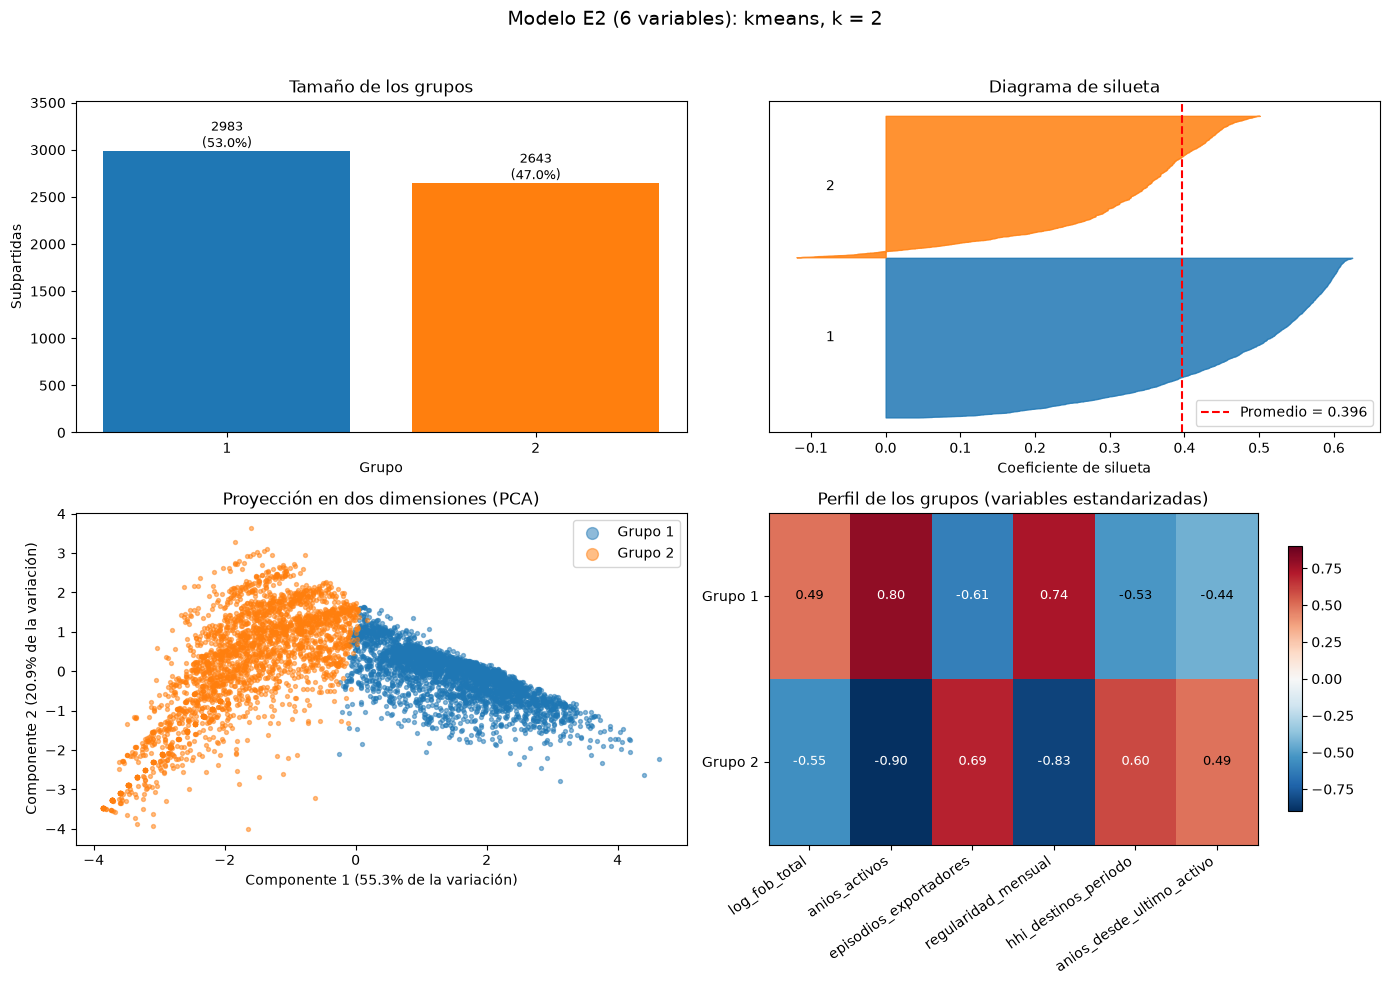

Promedios por grupo, modelo E2 (unidades originales)
       subpartidas  log_fob_total  anios_activos  episodios_exportadores  regularidad_mensual  hhi_destinos_periodo  anios_desde_ultimo_activo
grupo                                                                                                                                         
1             2983           1.87          14.64                    1.18                 0.68                  0.34                       0.04
2             2643           0.21           6.08                    2.69                 0.16                  0.65                       2.63



In [8]:
# Generación de gráficos y perfiles del modelo E2.
graficar_modelo("E2", k_usado["E2"])

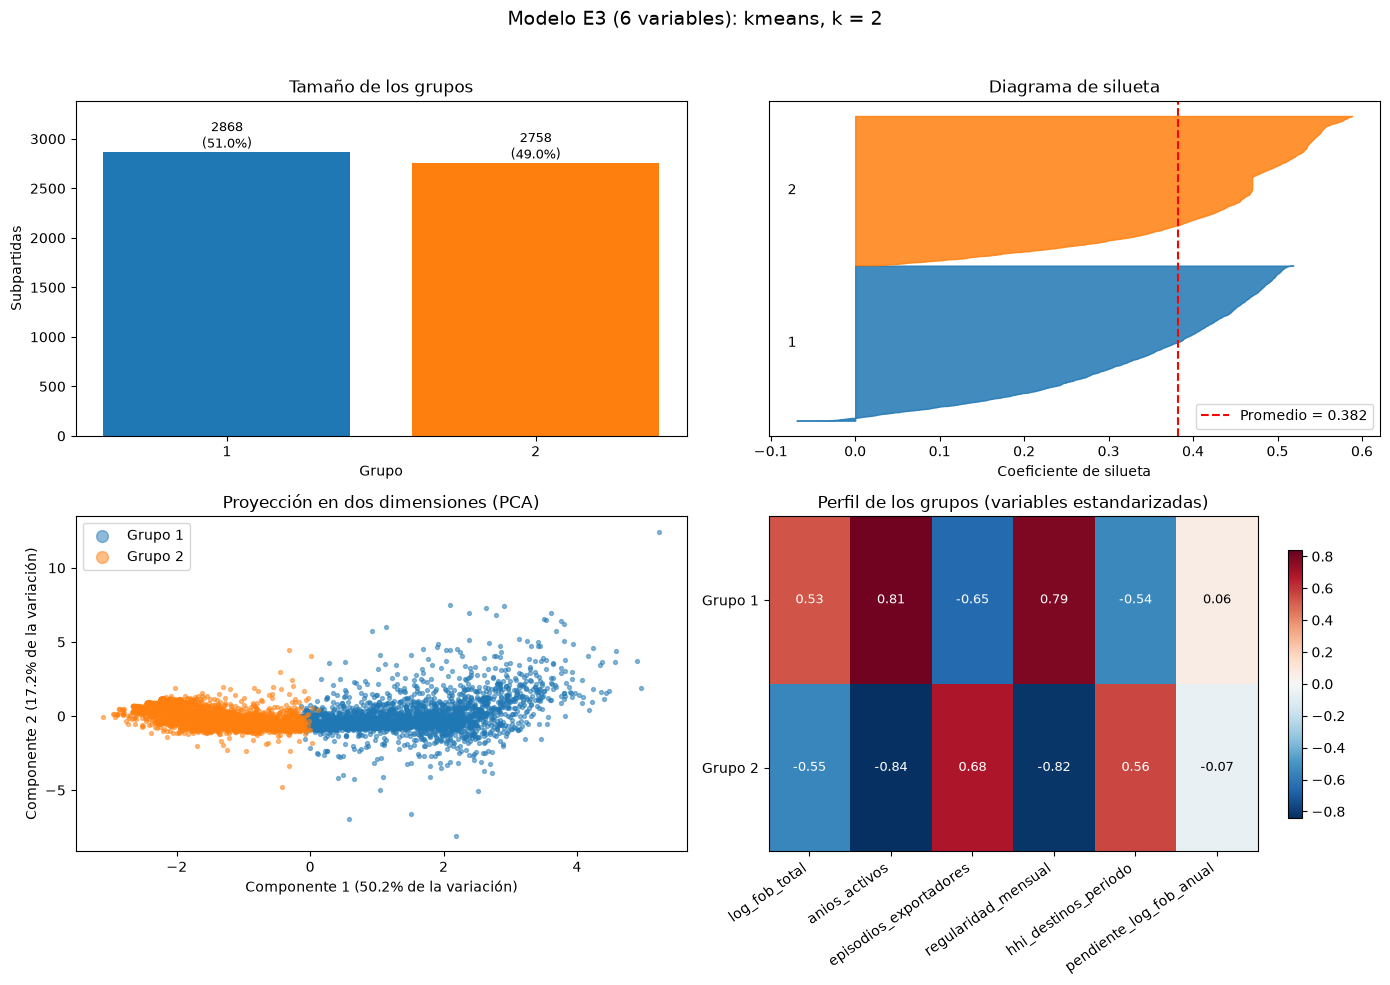

Promedios por grupo, modelo E3 (unidades originales)
       subpartidas  log_fob_total  anios_activos  episodios_exportadores  regularidad_mensual  hhi_destinos_periodo  pendiente_log_fob_anual
grupo                                                                                                                                       
1             2868           1.93          14.69                    1.14                 0.70                  0.34                      0.0
2             2758           0.22           6.39                    2.67                 0.16                  0.64                     -0.0



In [9]:
# Generación de gráficos y perfiles del modelo E3.
graficar_modelo("E3", k_usado["E3"])

### Gráficos de los demás valores de k
Se guardan en la carpeta `figuras` los mismos cuatro gráficos para todos los k de `rango_k`, con k-means, para poder compararlos sin volver a ejecutar.
Los archivos se llaman `modelo_E1_kmeans_k3.png`, `modelo_E2_kmeans_k5.png`, etc.

In [10]:
# Generación y almacenamiento de gráficos para todos los valores de K evaluados.
if guardar_figuras and guardar_todos_los_k:
    for m in modelos:
        for metodo in metodos:
            for k in rango_k:
                graficar_modelo(m, k, metodo, mostrar=False)
    print("Gráficos guardados en:", (carpeta_salida / "figuras").resolve())
else:
    print("No se guardaron los gráficos de los demás k.")

Gráficos guardados en: C:\Users\Udep titulación\Downloads\TESIS_HOMOLOGACION_SUBPARTIDAS\Clustering_E1_E2_E3_v3\figuras


In [14]:
from sklearn.metrics import adjusted_rand_score
import pandas as pd

# Comparación de las configuraciones para dos y tres grupos
pares = [("E1", "E2"), ("E1", "E3"), ("E2", "E3")]
tabla_ari = pd.DataFrame(index=["E1 y E2", "E1 y E3", "E2 y E3"])

for k in (2, 3):
    grupos = {modelo: asignar(modelo, k) for modelo in modelos}
    valores_ari = []

    for a, b in pares:
        assert grupos[a].index.equals(grupos[b].index)
        valores_ari.append(adjusted_rand_score(grupos[a], grupos[b]))

    tabla_ari[f"k={k}"] = valores_ari

tabla_ari.index.name = "Configuraciones comparadas"
display(tabla_ari.round(4))
tabla_ari.to_csv(carpeta_salida / "ari_entre_configuraciones.csv")



Comparación E1 vs E2
ARI entre modelos: 0.9077
Tabla de correspondencia de grupos:


E2,1,2
E1,,
1,2857,7
2,126,2636



Comparación E1 vs E3
ARI entre modelos: 0.9943
Tabla de correspondencia de grupos:


E3,1,2
E1,,
1,2862,2
2,6,2756



Comparación E2 vs E3
ARI entre modelos: 0.9117
Tabla de correspondencia de grupos:


E3,1,2
E2,,
1,2862,121
2,6,2637


## Comparación de E1, E2 y E3 con tres grupos

Se fija k = 3 en las tres configuraciones y se comparan los promedios de sus indicadores por grupo.

In [15]:
# Asignación de grupos para k=3 en cada modelo
k_analisis = {m: 3 for m in modelos}
etiquetas_k = {m: asignar(m, k_analisis[m]) for m in modelos}

### Promedios de los indicadores por grupo y configuración

In [17]:
# Cálculo y presentación de los perfiles promedio de los grupos para cada modelo.
for m in modelos:
    datos = resultados[m]["datos"]
    lab = etiquetas_k[m]
    tabla = datos.assign(grupo=lab).groupby("grupo")[modelos[m]].mean().round(4)
    tabla.insert(0, "subpartidas", lab.value_counts().sort_index())
    print(f"Modelo {m}, k = {k_analisis[m]}")
    print(tabla.to_string())
    print()

Modelo E1, k = 3
       subpartidas  log_fob_total  anios_activos  episodios_exportadores  regularidad_mensual  hhi_destinos_periodo
grupo                                                                                                              
1             2692         2.0261        14.7675                  1.0732               0.7247                0.3397
2             1780         0.3132         9.3404                  3.1865               0.1974                0.4564
3             1154         0.1125         2.9289                  1.7938               0.1280                0.8769

Modelo E2, k = 3
       subpartidas  log_fob_total  anios_activos  episodios_exportadores  regularidad_mensual  hhi_destinos_periodo  anios_desde_ultimo_activo
grupo                                                                                                                                         
1             2713         2.0116        14.7788                  1.0822               0.7212      

# EXPORTACIÓN DEFINITIVA: E1 CON TRES CLÚSTERES

In [23]:
from pathlib import Path
import pandas as pd

# 1. Recuperación de los indicadores y las etiquetas definitivas de E1.
base_final = resultados["E1"]["datos"].copy()

base_final["grupo_E1"] = (
    etiquetas_k["E1"]
    .reindex(base_final.index)
)

# 2. Validación de la cantidad de registros, las etiquetas y los resultados esperados.
assert k_analisis["E1"] == 3
assert len(base_final) == 5626
assert base_final["grupo_E1"].notna().all()

base_final["grupo_E1"] = base_final["grupo_E1"].astype(int)

conteo = base_final["grupo_E1"].value_counts().sort_index()

assert conteo.to_dict() == {
    1: 2692,
    2: 1780,
    3: 1154
}, "Los tamaños de los grupos no coinciden."

assert base_final["subpartida_homologada"].nunique() == 5626

fob_total = base_final["fob_total_mill"].sum()

assert abs(fob_total - 706350.99034) < 0.01

# 3. Carpeta de salida de la clasificación final
carpeta = carpeta_salida

# 4. Exportación de los resultados en formatos Parquet y CSV.
base_final.to_parquet(
    carpeta / "subpartidas_E1_k3_FINAL.parquet",
    index=False
)

base_final.to_csv(
    carpeta / "subpartidas_E1_k3_FINAL.csv",
    index=False,
    encoding="utf-8-sig"
)

# 5. Presentación del resumen de validación y la ubicación de los archivos.
print("RESULTADOS DEFINITIVOS DE E1")
print("\nSubpartidas:", len(base_final))
print("\nSubpartidas por grupo:")
print(conteo.to_string())
print("\nFOB total:", round(fob_total, 2))
print("\nArchivos guardados en:")
print(carpeta)


RESULTADOS DEFINITIVOS DE E1

Subpartidas: 5626

Subpartidas por grupo:
grupo_E1
1    2692
2    1780
3    1154

FOB total: 706350.99

Archivos guardados en:
C:\Users\Udep titulación\Downloads\TESIS_HOMOLOGACION_SUBPARTIDAS\Clustering_E1_E2_E3_v3\E1_k3_DEFINITIVO
